# DQI cho bài xếp giảng viên trên lịch kiểu FPT

Notebook đi qua toàn bộ quy trình Decoded Quantum Interferometry (DQI, Jordan et al., arXiv:2408.08292) cho bài gán giảng viên (teacher) cho lớp: dựng dữ liệu, viết bài toán thành max-LINSAT, dựng mạch, giải mã, đo và chấm kết quả.

Dữ liệu lấy từ bộ `toy` của ttqaoa, bộ duy nhất có mã môn thật của trường (CSD203, PFP191, ...) và khung lịch 4 ca mỗi ngày. Ta rút ra một ngày học: thứ 2, 4 ca, mỗi ca 2 lớp trùng giờ, 3 môn, 3 teacher.
- **Buổi sáng** (ca 1, 2; 4 lớp) đủ nhỏ để chạy mạch thật (26 qubit) và đo từng thanh ghi sau mỗi bước, nên mỗi bước DQI có một ô kiểm tra so với công thức (phần 4 đến 11).
- **Cả ngày** (8 lớp, có quota) dùng để so DQI với random, CP-SAT và QAOA của ttqaoa (phần 12).

Mỗi phần ghi mục tiêu, input, output, phương pháp, và lý do hay cách kiểm tra khi có. Đặc tả đầy đủ (formulation, metric, các bước DQI) ở Notion: [SPEC-002](https://app.notion.com/p/3fb52101ba75813b9b23c3b2557d9ef7).

| Phần | Nội dung |
|---|---|
| 1 | Dữ liệu gốc: bộ `toy` của ttqaoa |
| 2 | Dựng một ngày học kiểu FPT từ `toy` |
| 3 | Xử lý dữ liệu thành `Instance` |
| 4 | Formulation max-LINSAT (buổi sáng) |
| 5 | Code mà decoder phải giải |
| 6 to 11 | Các bước của DQI: trọng số, Dicke, nạp giá trị, syndrome, giải mã, Fourier và đo |
| 12 | Cả ngày: so DQI với random, CP-SAT, QAOA |
| 13 | Tóm tắt |

Chạy với `uv sync --all-groups`. Dữ liệu đọc và ghi trong `$DQITT_DATA` (mặc định `/home/al/Data`).

In [1]:
import csv
import math
import time
from itertools import product

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from loguru import logger
from qmos_qaoa.solver import solve_qaoa

from dqitt import paths
from dqitt.circuit import DQICircuit, n_wires, row_coeffs
from dqitt.classical import cpsat_optimum, optimum
from dqitt.dqi import all_x, expected_satisfied, ideal_state, l1_probs, l1_weights, theory_weights
from dqitt.formulations import binary, to_assignment
from dqitt.metrics import shots_to_hit
from dqitt.problem import brute_force, build, code_distance, decoder_failure, error_patterns, load, violations
from dqitt.ttqaoa import bits_to_assignment, index_to_bits, qaoa_probs, qubo

logger.remove()
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)
TOY = paths.DATA / "ttqaoa" / "toy"
OUT = paths.DATA / "dqitt" / "fpt_toy"


def read_matrix(path):
    """CSV with a header row and a label column -> (columns, {label: [values]})."""
    rows = list(csv.reader(path.open()))
    return rows[0][1:], {r[0].strip(): r[1:] for r in rows[1:]}


def short(teacher):
    return teacher.split("@")[0]

## 1. Dữ liệu gốc: bộ `toy` của ttqaoa

**Mục tiêu.** Xem bộ `toy` có gì và thiếu gì trước khi dùng.

**Input.** 7 file CSV trong `$DQITT_DATA/ttqaoa/toy` (chép nguyên từ ttqaoa, commit `3b494c1`): `Task` (lớp, môn, mã slot), `InstructorSkill` (điểm kỹ năng teacher theo môn), `InstructorSlot` (mức rảnh theo mã slot), `SlotConflict` (mã slot nào trùng giờ mã nào), `InstructorQuota` (số lớp tối thiểu, tối đa mỗi teacher), `slotDOTW` (mã slot nằm ở ca nào của ngày nào).

**Output.** Danh sách lớp và môn, khung lịch tuần, và các chỗ thiếu dữ liệu.

In [2]:
tasks = list(csv.DictReader((TOY / "Task.csv").open()))
print(f"Task.csv: {len(tasks)} lớp, môn {sorted({t['Subject'] for t in tasks})}")
dotw = list(csv.DictReader((TOY / "slotDOTW.csv").open()))
print(f"\nslotDOTW.csv\n{'':10s}" + "".join(f"ca {c:<11s}" for c in "1234"))
for r in dotw:
    print(f"{r['Day']:10s}" + "".join(f"{r[c]:<14s}" for c in "1234"))

Task.csv: 18 lớp, môn ['CSD203', 'CSD204', 'DBI202', 'DBI203', 'PFP191', 'PRF192']

slotDOTW.csv
          ca 1          ca 2          ca 3          ca 4          
Monday    A24, A25      A42, A52      P24, P25      P42, P52      
Tuesday   A35, A36      A53, A63      P35, P36      P53, P63      
Wednesday A42, A46      A24, A64      P42, P46      P24, P64      
Thursday  A52, A53      A25, A35      P52, P53      P25, P35      
Friday    A63, A64      A36, A46      P63, P64      P36, P46      
Saturday  A77           A77           P77           P77           


Mỗi ô của `slotDOTW` chứa 2 mã slot. Gom ngược lại: mỗi mã slot học ở những buổi nào trong tuần.

In [3]:
sessions = {}
for r in dotw:
    for c in "1234":
        for slot in {x.strip() for x in r[c].split(",")}:
            sessions.setdefault(slot, []).append(f"{r['Day'][:3]} ca {c}")
for slot in sorted(sessions):
    print(f"{slot}: {sessions[slot]}")

A24: ['Mon ca 1', 'Wed ca 2']
A25: ['Mon ca 1', 'Thu ca 2']
A35: ['Tue ca 1', 'Thu ca 2']
A36: ['Tue ca 1', 'Fri ca 2']
A42: ['Mon ca 2', 'Wed ca 1']
A46: ['Wed ca 1', 'Fri ca 2']
A52: ['Mon ca 2', 'Thu ca 1']
A53: ['Tue ca 2', 'Thu ca 1']
A63: ['Tue ca 2', 'Fri ca 1']
A64: ['Wed ca 2', 'Fri ca 1']
A77: ['Sat ca 1', 'Sat ca 2']
P24: ['Mon ca 3', 'Wed ca 4']
P25: ['Mon ca 3', 'Thu ca 4']
P35: ['Tue ca 3', 'Thu ca 4']
P36: ['Tue ca 3', 'Fri ca 4']
P42: ['Mon ca 4', 'Wed ca 3']
P46: ['Wed ca 3', 'Fri ca 4']
P52: ['Mon ca 4', 'Thu ca 3']
P53: ['Tue ca 4', 'Thu ca 3']
P63: ['Tue ca 4', 'Fri ca 3']
P64: ['Wed ca 4', 'Fri ca 3']
P77: ['Sat ca 3', 'Sat ca 4']


Chỗ thiếu: `InstructorSlot` chỉ có lịch rảnh cho một phần các mã slot mà `Task` dùng. ttqaoa coi mã slot thiếu là không rảnh (mức 0).

In [4]:
slot_cols, _ = read_matrix(TOY / "InstructorSlot.csv")
toy = load(TOY)
print("InstructorSlot có lịch rảnh cho:", slot_cols)
print("mã slot Task dùng nhưng không có lịch rảnh:", sorted({t["Slot"] for t in tasks} - set(slot_cols)))
print("số lớp không có teacher nào dạy được:", sum(not e for e in toy.eligible), "/", len(toy.eligible))

InstructorSlot có lịch rảnh cho: ['A24', 'P52', 'A25', 'P53', 'A63', 'P64']
mã slot Task dùng nhưng không có lịch rảnh: ['A35', 'A42', 'A46', 'A53', 'A64', 'P24', 'P25', 'P46', 'P63']
số lớp không có teacher nào dạy được: 11 / 18


## 2. Dựng một ngày học kiểu FPT từ `toy`

**Mục tiêu.** Một bộ dữ liệu nhỏ, đúng khung 4 ca mỗi ngày, mỗi ca 2 lớp trùng giờ, dùng mã môn và lớp thật của `toy`, và không lớp nào thiếu người dạy.

**Input.** Các file của `toy` ở phần 1.

**Output.** Hai bộ CSV cùng layout ttqaoa trong `$DQITT_DATA/dqitt/fpt_toy/`: `day` (cả thứ 2, 8 lớp) và `am` (buổi sáng, 4 lớp).

**Phương pháp.** Năm bước chọn dưới đây, mỗi bước một quy tắc. Ngoài lịch rảnh (bước 2.5), mọi giá trị đều lấy nguyên từ `toy`.

### 2.1 Chọn ngày và ca

**Quy tắc.** Lấy thứ 2 trong `slotDOTW`: 4 ca, mỗi ca 2 mã slot, tổng 8 mã. Cặp conflict lấy từ `SlotConflict` của `toy`, chỉ giữ các cặp giữa 8 mã này.

**Lý do.** Mỗi mã slot học 2 buổi một tuần (phần 1), nên hai mã có thể trùng giờ ở một ngày khác. Kiểm tra dưới cho thấy trong 8 mã của thứ 2, chỉ hai mã cùng ca là conflict.

In [5]:
monday = next(r for r in dotw if r["Day"] == "Monday")
cas = {c: [x.strip() for x in monday[c].split(",")] for c in "1234"}
codes = [s for c in cas.values() for s in c]
conf_cols, conf = read_matrix(TOY / "SlotConflict.csv")
slot_pairs = [(a, b) for i, a in enumerate(codes) for b in codes[i + 1:] if conf[a][conf_cols.index(b)] == "1"]
print("ca của thứ 2:", cas)
print("cặp conflict giữa 8 mã:", slot_pairs)

ca của thứ 2: {'1': ['A24', 'A25'], '2': ['A42', 'A52'], '3': ['P24', 'P25'], '4': ['P42', 'P52']}
cặp conflict giữa 8 mã: [('A24', 'A25'), ('A42', 'A52'), ('P24', 'P25'), ('P42', 'P52')]


### 2.2 Chọn teacher

**Quy tắc.** Bỏ teacher có quota tối đa bằng 1; giữ 3 teacher còn lại.

**Lý do.** DQI làm việc trên $\mathbb{F}_p$ với $p$ là số nguyên tố nhỏ nhất $\ge$ số teacher (phần 4). 3 teacher cho $p=3$, mỗi ô trong mạch cần 2 qubit, và mạch buổi sáng là 26 qubit, còn mô phỏng được. 4 teacher cho $p=5$, 3 qubit mỗi ô, và mạch buổi sáng lên 36 qubit. Teacher bị bỏ là người chỉ được dạy tối đa 1 lớp.

In [6]:
quota = {r[""].strip(): (int(r["Min quota"]), int(r["Max quota"])) for r in csv.DictReader((TOY / "InstructorQuota.csv").open())}
print("quota (min, max):", {short(t): q for t, q in quota.items()})
teachers = [t for t, (_, hi) in quota.items() if hi > 1]
print("giữ:", [short(t) for t in teachers])

quota (min, max): {'anhbn5': (1, 99), 'Ngadtt22': (1, 2), 'a': (1, 4), 'N': (1, 1)}
giữ: ['anhbn5', 'Ngadtt22', 'a']


### 2.3 Chọn môn

**Quy tắc.** Giữ các môn có đúng 2 trong 3 teacher dạy được (điểm kỹ năng $\ge5$).

**Lý do.** Môn chỉ 1 người dạy được thì lớp đó không có gì để chọn; 2 người thì mỗi lớp có đúng một lựa chọn thay thế, và hai lớp khác môn trong cùng ca có chung đúng một teacher, nên conflict có ý nghĩa.

In [7]:
skill_cols, skill = read_matrix(TOY / "InstructorSkill.csv")
can_teach = {s: [t for t in teachers if int(skill[t][skill_cols.index(s)]) >= 5] for s in skill_cols}
for s, ts in can_teach.items():
    print(f"{s}: {[short(t) for t in ts]}")
subjects = [s for s, ts in can_teach.items() if len(ts) == 2]
print("môn giữ:", subjects)

DBI202: ['Ngadtt22']
CSD203: ['Ngadtt22', 'a']
DBI203: ['anhbn5']
CSD204: ['anhbn5', 'a']
PFP191: ['anhbn5', 'Ngadtt22']
PRF192: ['a']
môn giữ: ['CSD203', 'CSD204', 'PFP191']


### 2.4 Chọn lớp và xếp vào ca

**Quy tắc.** Lấy 8 lớp đầu tiên trong `Task.csv` của `toy` có môn thuộc 3 môn ở trên, giữ nguyên tên lớp và môn, rồi xếp lần lượt vào 8 mã slot của thứ 2 (ca 1 đến ca 4, mỗi ca 2 lớp).

**Lý do.** Chỉ đổi slot: trong `toy` các lớp này rải khắp tuần, nhiều lớp ở mã slot không có lịch rảnh (phần 1).

In [8]:
picked = [t for t in tasks if t["Subject"] in subjects][:8]
rows = [(t["Class"], t["Subject"], slot) for t, slot in zip(picked, codes)]
for ca, slots in cas.items():
    line = [f"{slot} {c} {s} ({','.join(short(x) for x in can_teach[s])})" for c, s, slot in rows if slot in slots]
    print(f"ca {ca}: " + "  |  ".join(line))

ca 1: A24 AI1910 CSD203 (Ngadtt22,a)  |  A25 AI1912 CSD204 (anhbn5,a)
ca 2: A42 AI1914 CSD203 (Ngadtt22,a)  |  A52 AI1916 CSD204 (anhbn5,a)
ca 3: P24 AI1918 CSD203 (Ngadtt22,a)  |  P25 AI1920 CSD204 (anhbn5,a)
ca 4: P42 AI2007 PFP191 (anhbn5,Ngadtt22)  |  P52 AI1922 CSD203 (Ngadtt22,a)


### 2.5 Lịch rảnh

**Quy tắc.** Mọi teacher rảnh ở cả 8 mã slot (mức 5).

**Lý do.** `toy` chỉ có lịch rảnh cho 3/8 mã slot của thứ 2, và nếu dùng đúng các giá trị đó (mã thiếu tính là 0), nhiều lớp không ai dạy được. Ô dưới đếm cụ thể. Với quy tắc này, ai dạy được lớp nào chỉ còn phụ thuộc kỹ năng.

In [9]:
avail_cols, avail = read_matrix(TOY / "InstructorSlot.csv")
toy_avail = lambda t, slot: int(avail[t][avail_cols.index(slot)]) if slot in avail_cols else 0
print("lịch rảnh của toy tại 8 mã:", {short(t): {s: toy_avail(t, s) for s in codes} for t in teachers})
stuck = [c for c, s, slot in rows if not any(toy_avail(t, slot) >= 5 for t in can_teach[s])]
print(f"nếu dùng lịch rảnh của toy: {len(stuck)}/8 lớp không ai dạy được: {stuck}")

lịch rảnh của toy tại 8 mã: {'anhbn5': {'A24': 5, 'A25': 0, 'A42': 0, 'A52': 0, 'P24': 0, 'P25': 0, 'P42': 0, 'P52': 0}, 'Ngadtt22': {'A24': 0, 'A25': 5, 'A42': 0, 'A52': 0, 'P24': 0, 'P25': 0, 'P42': 0, 'P52': 5}, 'a': {'A24': 5, 'A25': 0, 'A42': 0, 'A52': 0, 'P24': 0, 'P25': 0, 'P42': 0, 'P52': 5}}
nếu dùng lịch rảnh của toy: 6/8 lớp không ai dạy được: ['AI1912', 'AI1914', 'AI1916', 'AI1918', 'AI1920', 'AI2007']


### 2.6 Ghi ra file

Ghi hai bộ: `day` (8 lớp) và `am` (4 lớp của ca 1, 2). Mỗi bộ có đủ 5 file theo layout ttqaoa, chỉ chứa các mã slot, môn và teacher đã chọn.

In [10]:
def write_dataset(out, rows):
    out.mkdir(parents=True, exist_ok=True)
    slots = [r[2] for r in rows]

    def dump(name, header, body):
        with (out / name).open("w", newline="") as f:
            w = csv.writer(f)
            w.writerow(header)
            w.writerows(body)

    dump("Task.csv", ["Class", "Subject", "Slot"], rows)
    dump("InstructorSkill.csv", [""] + subjects, [[t] + [skill[t][skill_cols.index(s)] for s in subjects] for t in teachers])
    dump("InstructorSlot.csv", [""] + slots, [[t] + [5] * len(slots) for t in teachers])
    dump("SlotConflict.csv", [""] + slots, [[a] + [conf[a][conf_cols.index(b)] for b in slots] for a in slots])
    dump("InstructorQuota.csv", ["", "Min quota", "Max quota"], [[t, *quota[t]] for t in teachers])


write_dataset(OUT / "day", rows)
write_dataset(OUT / "am", [r for r in rows if r[2] in cas["1"] + cas["2"]])
for d in ("day", "am"):
    print(f"--- {d}/Task.csv\n{(OUT / d / 'Task.csv').read_text()}")

--- day/Task.csv
Class,Subject,Slot
AI1910,CSD203,A24
AI1912,CSD204,A25
AI1914,CSD203,A42
AI1916,CSD204,A52
AI1918,CSD203,P24
AI1920,CSD204,P25
AI2007,PFP191,P42
AI1922,CSD203,P52

--- am/Task.csv
Class,Subject,Slot
AI1910,CSD203,A24
AI1912,CSD204,A25
AI1914,CSD203,A42
AI1916,CSD204,A52



## 3. Xử lý dữ liệu thành `Instance`

**Mục tiêu.** Rút từ các bảng ra ba thứ bài toán dùng: tập teacher dạy được mỗi lớp $E_s$, các cặp lớp trùng giờ, và quota.

**Input.** Thư mục CSV ở phần 2.

**Output.** `Instance` với `eligible` ($E_s$), `conflicts` (cặp lớp), `quota`.

**Phương pháp.** `problem.load`: teacher $t$ dạy được lớp $s$ khi điểm kỹ năng môn của $s$ và mức rảnh ở slot của $s$ đều $\ge5$, cùng ngưỡng với `TimetableProblem` của ttqaoa. Hai lớp conflict khi ô `SlotConflict` của hai slot bằng 1.

**Lý do.** Mọi bước sau chỉ dùng ba thứ này; không cần quay lại bảng gốc.

In [11]:
day, am = load(OUT / "day"), load(OUT / "am")
T = day.teachers
for name, x in (("cả ngày", day), ("buổi sáng", am)):
    print(f"{name}: {len(x.sections)} lớp, {len(x.teachers)} teacher, quota {x.quota}")
    for sec, slot, E in zip(x.sections, x.slots, x.eligible):
        print(f"   {sec} ({slot}): E = {[short(T[t]) for t in sorted(E)]}")
    print("   conflict:", [(x.sections[a], x.sections[b]) for a, b in x.conflicts])

cả ngày: 8 lớp, 3 teacher, quota [(1, 99), (1, 2), (1, 4)]
   AI1910 (A24): E = ['Ngadtt22', 'a']
   AI1912 (A25): E = ['anhbn5', 'a']
   AI1914 (A42): E = ['Ngadtt22', 'a']
   AI1916 (A52): E = ['anhbn5', 'a']
   AI1918 (P24): E = ['Ngadtt22', 'a']
   AI1920 (P25): E = ['anhbn5', 'a']
   AI2007 (P42): E = ['anhbn5', 'Ngadtt22']
   AI1922 (P52): E = ['Ngadtt22', 'a']
   conflict: [('AI1910', 'AI1912'), ('AI1914', 'AI1916'), ('AI1918', 'AI1920'), ('AI2007', 'AI1922')]
buổi sáng: 4 lớp, 3 teacher, quota [(1, 99), (1, 2), (1, 4)]
   AI1910 (A24): E = ['Ngadtt22', 'a']
   AI1912 (A25): E = ['anhbn5', 'a']
   AI1914 (A42): E = ['Ngadtt22', 'a']
   AI1916 (A52): E = ['anhbn5', 'a']
   conflict: [('AI1910', 'AI1912'), ('AI1914', 'AI1916')]


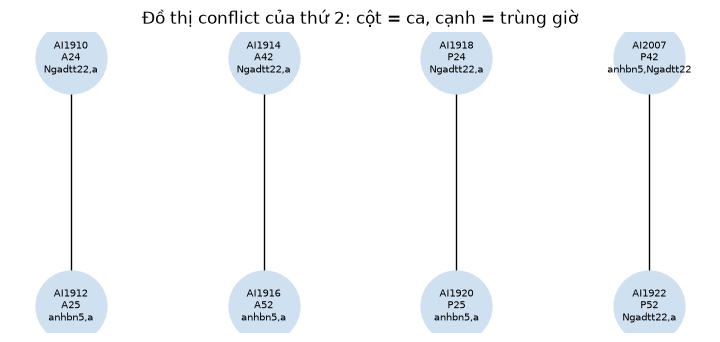

In [12]:
G = nx.Graph()
G.add_nodes_from(day.sections)
G.add_edges_from((day.sections[a], day.sections[b]) for a, b in day.conflicts)
labels = {s: f"{s}\n{slot}\n{','.join(short(T[t]) for t in sorted(E))}" for s, slot, E in zip(day.sections, day.slots, day.eligible)}
plt.figure(figsize=(7, 3))
nx.draw(G, {s: (i // 2, -(i % 2)) for i, s in enumerate(day.sections)}, labels=labels, node_color="#cfe0f0", node_size=2600, font_size=7)
plt.title("Đồ thị conflict của thứ 2: cột = ca, cạnh = trùng giờ")
plt.show()

## 4. Formulation: viết bài toán thành max-LINSAT (buổi sáng)

Từ phần này tới phần 11 dùng buổi sáng (4 lớp), để chạy được mạch thật.

**Mục tiêu.** Đưa bài toán về dạng DQI nhận: bộ $(p,B,F)$. Lịch $y\in\mathbb{F}_p^n$ thoả row $i$ khi $b_i\cdot y\bmod p\in F_i$; ta muốn thoả nhiều row nhất (Def. 2.1 của Jordan et al.).

**Input.** `Instance` buổi sáng.

**Output.** `Linsat`: $p$, ma trận $B$ cỡ $m\times n$, các tập $F_i$.

**Phương pháp.**
- Biến $y_s$ là teacher của lớp $s$, nên $n$ là số lớp; $p$ là số nguyên tố nhỏ nhất $\ge$ số teacher.
- Mỗi cặp conflict $(a,b)$ cho row $y_a+(p-1)y_b$, tức $y_a-y_b$, với $F=\{1,\dots,p-1\}$: thoả khi hai lớp khác teacher.
- Mỗi lớp cho row $y_s$ với $F=E_s$; bỏ row nếu mọi giá trị đều thuộc $E_s$.

**Lý do.** Mỗi lớp chỉ có một biến nên ràng buộc "đúng một teacher" tự thoả. Phép mod $p$ đến từ DQI: các bước Fourier và giải mã làm trên $\mathbb{F}_p$, nên $p$ phải nguyên tố. Quota là phép đếm số lớp của một teacher, không viết được thành một row tuyến tính theo $y$; phần 12 dùng encoding khác để có quota.

In [13]:
inst = am
lin = build(inst)
print(f"p = {lin.p}, n = {lin.n} biến, m = {lin.m} row")
meaning = [f"conflict {inst.sections[a]}-{inst.sections[b]}" for a, b in inst.conflicts] + [
    f"eligibility {inst.sections[s]}" for s, E in enumerate(inst.eligible) if 0 < len(E) < lin.p
]
for i in range(lin.m):
    print(f"row {i}: b = {lin.B[i]}, F = {np.flatnonzero(lin.F[i]).tolist()}   ({meaning[i]})")

p = 3, n = 4 biến, m = 6 row
row 0: b = [1 2 0 0], F = [1, 2]   (conflict AI1910-AI1912)
row 1: b = [0 0 1 2], F = [1, 2]   (conflict AI1914-AI1916)
row 2: b = [1 0 0 0], F = [1, 2]   (eligibility AI1910)
row 3: b = [0 1 0 0], F = [0, 2]   (eligibility AI1912)
row 4: b = [0 0 1 0], F = [1, 2]   (eligibility AI1914)
row 5: b = [0 0 0 1], F = [0, 2]   (eligibility AI1916)


Vét cạn mọi lịch để có mốc so sánh: điểm tối ưu, các lịch đạt điểm đó, và mức của lịch chọn ngẫu nhiên đều trên $\mathbb{F}_p^n$.

In [14]:
X = all_x(lin.p, lin.n)
s = lin.count(X)
opt, best = brute_force(lin)
print(f"tối ưu {opt}/{lin.m}, đạt ở {len(best)} lịch:")
for y in best:
    print("  ", {sec: short(T[t]) for sec, t in zip(inst.sections, y)})
print(f"random: <s>/m = {s.mean() / lin.m:.4f}, P(tối ưu) = {(s == opt).mean():.4f}")

tối ưu 6/6, đạt ở 9 lịch:
   {'AI1910': 'Ngadtt22', 'AI1912': 'anhbn5', 'AI1914': 'Ngadtt22', 'AI1916': 'anhbn5'}
   {'AI1910': 'Ngadtt22', 'AI1912': 'anhbn5', 'AI1914': 'Ngadtt22', 'AI1916': 'a'}
   {'AI1910': 'Ngadtt22', 'AI1912': 'anhbn5', 'AI1914': 'a', 'AI1916': 'anhbn5'}
   {'AI1910': 'Ngadtt22', 'AI1912': 'a', 'AI1914': 'Ngadtt22', 'AI1916': 'anhbn5'}
   {'AI1910': 'Ngadtt22', 'AI1912': 'a', 'AI1914': 'Ngadtt22', 'AI1916': 'a'}
   {'AI1910': 'Ngadtt22', 'AI1912': 'a', 'AI1914': 'a', 'AI1916': 'anhbn5'}
   {'AI1910': 'a', 'AI1912': 'anhbn5', 'AI1914': 'Ngadtt22', 'AI1916': 'anhbn5'}
   {'AI1910': 'a', 'AI1912': 'anhbn5', 'AI1914': 'Ngadtt22', 'AI1916': 'a'}
   {'AI1910': 'a', 'AI1912': 'anhbn5', 'AI1914': 'a', 'AI1916': 'anhbn5'}
random: <s>/m = 0.6667, P(tối ưu) = 0.1111


Chấm hai lịch: lịch tối ưu đầu tiên, và cũng lịch đó nhưng hai lớp của ca 1 cùng được giao cho teacher mà cả hai lớp đều dạy được.

In [15]:
good = best[0]
bad = good.copy()
bad[0] = bad[1] = min(inst.eligible[0] & inst.eligible[1])
for y in (good, bad):
    ok = lin.satisfied(y)
    print({sec: short(T[t]) for sec, t in zip(inst.sections, y)}, "->", int(ok.sum()), "/", lin.m,
          "row thoả; hỏng:", [meaning[i] for i in np.flatnonzero(~ok)])

{'AI1910': 'Ngadtt22', 'AI1912': 'anhbn5', 'AI1914': 'Ngadtt22', 'AI1916': 'anhbn5'} -> 6 / 6 row thoả; hỏng: []
{'AI1910': 'a', 'AI1912': 'a', 'AI1914': 'Ngadtt22', 'AI1916': 'anhbn5'} -> 5 / 6 row thoả; hỏng: ['conflict AI1910-AI1912']


## 5. Code mà decoder phải giải

**Mục tiêu.** Biết trước bước giải mã (phần 10) khó tới đâu.

**Input.** Ma trận $B$.

**Output.** Khoảng cách $d$ của code $C^\perp=\{e\in\mathbb{F}_p^m: B^Te=0\}$, các codeword nhỏ nhất, và $\varepsilon_k$.

**Phương pháp.** $d$ là số row ít nhất có một tổ hợp tuyến tính khác 0 bằng vector 0, tìm bằng vét cạn. $\varepsilon_k$ là tỉ lệ error có đúng $k$ ô khác 0 mà một decoder trọng số nhỏ nhất lý tưởng không khôi phục duy nhất từ syndrome $B^Te$.

**Lý do.** Mạch DQI chỉ xoá được thanh ghi error nếu suy ngược được error từ syndrome. Với tối đa $\ell$ ô khác 0, việc này luôn làm được khi $2\ell+1\le d$.

In [16]:
d = code_distance(lin, max_w=4)
E3 = error_patterns(lin.m, lin.p, 3)
codewords = E3[((E3 @ lin.B) % lin.p == 0).all(axis=1)]
supports = sorted({tuple(int(i) for i in np.flatnonzero(e)) for e in codewords})
print(f"d = {d}; {len(codewords)} codeword trọng số 3 = {len(supports)} tập row x {lin.p - 1} bội số khác 0")
for rows_ in supports:
    e = next(c for c in codewords if tuple(np.flatnonzero(c)) == rows_)
    print(f"  rows {rows_}, hệ số {e[list(rows_)].tolist()}: {[meaning[i] for i in rows_]}")
print("ε_0, ε_1, ε_2 =", decoder_failure(lin, 2).round(4))

d = 3; 4 codeword trọng số 3 = 2 tập row x 2 bội số khác 0
  rows (0, 2, 3), hệ số [1, 2, 1]: ['conflict AI1910-AI1912', 'eligibility AI1910', 'eligibility AI1912']
  rows (1, 4, 5), hệ số [1, 2, 1]: ['conflict AI1914-AI1916', 'eligibility AI1914', 'eligibility AI1916']


ε_0, ε_1, ε_2 = [0.  0.  0.4]


## 6. Bước 1 của DQI: chọn trọng số

**Mục tiêu.** Chọn độ sâu $\ell$ và vector $w=(w_0,\dots,w_\ell)$. Trạng thái cuối có biên độ tỉ lệ với một đa thức bậc $\ell$ của các row; $w_k$ là phần dành cho error có đúng $k$ row được chọn.

**Input.** $(p,B,F)$ và $\ell$.

**Output.** $w$ với $\|w\|=1$.

**Phương pháp.** Jordan et al. (Lemma 9.2) cho $w$ là vector riêng chính của một ma trận tam đường chéo, với điều kiện mọi $|F_i|$ bằng nhau và $2\ell+1<d$. dqitt tính trực tiếp: dựng các trạng thái $|P_k\rangle$ trên toàn bộ $\mathbb{F}_p^n$ rồi giải bài toán trị riêng suy rộng để $\langle s\rangle$ lớn nhất (`dqi.ideal_state`). Với $\ell=1$ còn có công thức đóng `dqi.l1_weights` không cần liệt kê $\mathbb{F}_p^n$; phần 12 cần nó.

**Lý do.** Phần 5 cho $d=3$, nên $2\ell+1<d$ sai ngay từ $\ell=1$. Ô dưới so dự đoán của công thức với giá trị tính trực tiếp.

In [17]:
r = lin.F.sum(axis=1)
print("|F_i| =", r.tolist())
for l in (1, 2):
    w_th, frac_th = theory_weights(lin.m, l, lin.p, int(r[0]))
    psi, _, w = ideal_state(lin, l)
    print(f"l={l}: công thức tam đường chéo w = {w_th}, dự đoán <s>/m = {frac_th:.4f}")
    print(f"     tính trực tiếp          w = {w}, <s>/m thật = {expected_satisfied(psi, lin, X) / lin.m:.4f}")
psi1, _, w1 = ideal_state(lin, 1)
psi2, _, w2 = ideal_state(lin, 2)
print("công thức đóng l1_weights:", l1_weights(lin))

|F_i| = [2, 2, 2, 2, 2, 2]
l=1: công thức tam đường chéo w = [0.7559 0.6547], dự đoán <s>/m = 0.8333
     tính trực tiếp          w = [0.7071 0.7071], <s>/m thật = 0.8591
l=2: công thức tam đường chéo w = [0.5278 0.7038 0.4755], dự đoán <s>/m = 0.9233


     tính trực tiếp          w = [0.4918 0.5958 0.635 ], <s>/m thật = 0.9553
công thức đóng l1_weights: [0.7071 0.7071]


## 7. Bước 2: Dicke state trên thanh ghi flag

Mạch của dqitt có ba thanh ghi: $m$ qubit flag, $m$ ô error và $n$ ô syndrome; mỗi ô giữ một ký hiệu $\mathbb{F}_p$ bằng $\lceil\log_2p\rceil$ qubit. Mạch chia thành 5 stage: `dicke`, `load`, `syndrome`, `decode`, `qft`. `register_probs(register, upto)` chạy mạch tới hết stage `upto` rồi đo một thanh ghi, nên từng bước kiểm được riêng. Dựng hai mạch, $\ell=1$ và $\ell=2$.

**Mục tiêu.** Với mỗi $k$, chồng chập đều mọi cách chọn $k$ row trong $m$, với biên độ tổng $w_k$.

**Input.** $w$ ở phần 6.

**Output.** $\sum_kw_k\binom mk^{-1/2}\sum_{|\mu|=k}|\mu\rangle$ trên các qubit flag; $\mu_i=1$ nghĩa là row $i$ được chọn.

**Phương pháp.** Nạp thẳng vector trên bằng `StatePrep` (stage `dicke`). Tutorial PennyLane dựng bằng các khối SCS; cách nạp thẳng chỉ hợp với $m$ nhỏ vì vector có $2^m$ phần tử.

**Kiểm tra.** Xác suất thanh ghi flag có đúng $k$ bit 1 phải bằng $w_k^2$.

In [18]:
circ1 = DQICircuit(lin, 1, w1, device="lightning.qubit")
circ2 = DQICircuit(lin, 2, w2, device="lightning.qubit")
q = circ1.q
print(f"qubit: {circ1.n_wires} = flag {lin.m} + error {lin.m * q} + syndrome {lin.n * q}")
flags = circ1.register_probs("flags", upto="dicke")
k = np.indices(flags.shape).sum(axis=0)
print("P(có k bit 1), k=0,1:", [round(float(flags[k == j].sum()), 6) for j in (0, 1)], "   w² =", w1**2)

qubit: 26 = flag 6 + error 12 + syndrome 8


P(có k bit 1), k=0,1: [0.5, 0.5]    w² = [0.5 0.5]


## 8. Bước 3 và 4: nạp giá trị cho các row được chọn

**Mục tiêu.** Mỗi row được chọn nhận một giá trị $e\neq0$ trong ô error của nó, với biên độ $c_i(e)$ mang thông tin của $F_i$; sau đó xoá flag.

**Input.** Thanh ghi flag sau phần 7, các tập $F_i$.

**Output.** Thanh ghi error $\sum_k\frac{w_k}{\sqrt{\binom mk}}\sum_{|e|=k}\prod_{i:e_i\neq0}c_i(e_i)|e\rangle$, flag về 0.

**Phương pháp.** $c_i$ là biến đổi Fourier mod $p$ của $\tilde g_i$, hàm "row $i$ thoả" đã trừ trung bình và chia độ lệch chuẩn (`circuit.row_coeffs`). Flag $i$ điều khiển một unitary đưa $|0\rangle$ thành $\sum_ec_i(e)|e\rangle$ trên ô error $i$; sau đó flag $i$ được lật về 0 khi ô error khác 0 (stage `load`).

**Lý do.** $\tilde g_i$ có trung bình 0 nên $c_i(0)=0$: row được chọn luôn nhận giá trị khác 0, vì vậy flag suy được từ thanh ghi error và xoá được. Với $p=2$ chỉ có một giá trị khác 0, nên tutorial PennyLane làm bước này bằng cổng Z; với $p=3$ phải nạp cả vector $c_i$.

**Kiểm tra.** Flag về 0 với xác suất 1. Ở $\ell=1$, thanh ghi error phải có $P(e=0)=w_0^2$ và $P(\text{chỉ ô } i \text{ bằng } v)=w_1^2|c_i(v)|^2/m$.

In [19]:
for i in (0, len(inst.conflicts)):
    c = row_coeffs(lin, i)
    print(f"row {i} ({meaning[i]}): c = {np.round(c, 4)}, tổng |c|² = {np.sum(np.abs(c) ** 2):.4f}")
print("sau load, P(flag toàn 0) =", round(float(circ1.register_probs("flags", upto="load").flat[0]), 6))
err = circ1.register_probs("error", upto="load")
expected = np.zeros_like(err)
expected.flat[0] = w1[0] ** 2
for i in range(lin.m):
    c = row_coeffs(lin, i)
    for v in range(1, lin.p):
        idx = [0] * lin.m
        idx[i] = v
        expected[tuple(idx)] = w1[1] ** 2 * abs(c[v]) ** 2 / lin.m
print("thanh ghi error khớp công thức:", np.allclose(err, expected, atol=1e-9))

row 0 (conflict AI1910-AI1912): c = [ 0.    +0.j -0.7071-0.j -0.7071-0.j], tổng |c|² = 1.0000
row 2 (eligibility AI1910): c = [ 0.    +0.j -0.7071-0.j -0.7071-0.j], tổng |c|² = 1.0000


sau load, P(flag toàn 0) = 1.0


thanh ghi error khớp công thức: True


## 9. Bước 5: tính syndrome

**Mục tiêu.** Ghi $B^Te\bmod p$ vào thanh ghi syndrome.

**Input.** Thanh ghi error sau phần 8.

**Output.** $|e\rangle|B^Te\rangle$; syndrome dài $n$.

**Phương pháp.** Với mỗi $B_{ij}\neq0$, cộng $B_{ij}e_i$ vào ô syndrome $j$ theo mod $p$ bằng một cổng hoán vị trên hai ô (stage `syndrome`).

**Kiểm tra.** Phân bố của thanh ghi syndrome phải bằng phân bố error ở phần 8 đẩy qua phép $e\mapsto B^Te$.

In [20]:
e = np.zeros(lin.m, int)
e[0] = 1
print("error chỉ ở row 0, giá trị 1 -> syndrome", (e @ lin.B) % lin.p)
syn = circ1.register_probs("syndrome", upto="syndrome")
pushed = np.zeros_like(syn)
for idx in zip(*np.nonzero(err > 1e-15)):
    pushed[tuple((np.array(idx) @ lin.B) % lin.p)] += err[idx]
print("phân bố syndrome khớp:", np.allclose(syn, pushed, atol=1e-9))

error chỉ ở row 0, giá trị 1 -> syndrome [1 2 0 0]


phân bố syndrome khớp: True


## 10. Bước 6: giải mã và xoá error

**Mục tiêu.** Đưa thanh ghi error về 0 chỉ dựa vào syndrome.

**Input.** Thanh ghi syndrome $B^Te$.

**Output.** Thanh ghi error bằng 0 ở những nhánh decoder đúng.

**Phương pháp.** Bảng tra (`circuit.lookup_table`): với mỗi syndrome, lấy một error trọng số nhỏ nhất tạo ra nó (gặp trùng thì lấy cái đầu tiên), rồi trừ error đó khỏi thanh ghi error bằng cổng đa điều khiển theo syndrome (stage `decode`).

**Lý do.** Khi hai error trọng số $\le\ell$ có cùng syndrome, bảng chỉ xoá đúng một trong hai; nhánh còn lại để lại phần khác 0 trong thanh ghi error. Phần 5 cho biết điều này không xảy ra ở $\ell=1$ và xảy ra ở $\ell=2$.

**Kiểm tra.** Xác suất thanh ghi error bằng 0 sau stage này.

In [21]:
for l, circ in ((1, circ1), (2, circ2)):
    n_err = sum(math.comb(lin.m, j) * (lin.p - 1) ** j for j in range(1, l + 1))
    clean = circ.register_probs("error", upto="decode").flat[0]
    print(f"l={l}: {n_err} error có 1..{l} ô khác 0, bảng tra {len(circ.table)} dòng, "
          f"ε_{l} = {decoder_failure(lin, l)[l]:.4f}, sau decode P(error = 0) = {clean:.4f}")

l=1: 12 error có 1..1 ô khác 0, bảng tra 12 dòng, ε_1 = 0.0000, sau decode P(error = 0) = 1.0000


l=2: 72 error có 1..2 ô khác 0, bảng tra 52 dòng, ε_2 = 0.4000, sau decode P(error = 0) = 0.8656


## 11. Bước 7: Fourier, đo và chấm điểm

**Mục tiêu.** Đưa trạng thái về không gian lịch $y$, đo, và đánh giá.

**Input.** Thanh ghi syndrome sau phần 10.

**Output.** Phân bố của $y\in\mathbb{F}_p^n$ và các lịch lấy mẫu.

**Phương pháp.** Biến đổi Fourier mod $p$ trên từng ô syndrome (stage `qft`) rồi đo thanh ghi syndrome. Metric:
- $\langle s\rangle/m$: tỉ lệ row thoả kỳ vọng;
- $P(\text{tối ưu})$: xác suất một lần đo ra lịch tối ưu;
- $N_{95}$: số lần đo nhỏ nhất để $1-(1-P)^N\ge0.95$, tức 95% khả năng thấy ít nhất một lịch tối ưu.

**Kiểm tra.** So phân bố của mạch với trạng thái lý tưởng $|P(f)\rangle$ ở phần 6.

In [22]:
P1, P2 = circ1.probs_x(), circ2.probs_x()
print("l=1: mạch khớp trạng thái lý tưởng:", np.allclose(P1, np.abs(psi1) ** 2, atol=1e-10))
print("l=2: mạch khớp trạng thái lý tưởng:", np.allclose(P2, np.abs(psi2) ** 2, atol=1e-10))
dists = {
    "random": np.full(len(X), 1 / len(X)),
    "DQI l=1, mạch": P1,
    "DQI l=2, lý tưởng": np.abs(psi2) ** 2,
    "DQI l=2, mạch": P2,
}
print(f"\n{'cách':20s} {'<s>/m':>7s} {'P(tối ưu)':>10s} {'N95':>5s}")
for name, P in dists.items():
    p_opt = P[s == opt].sum()
    print(f"{name:20s} {P @ s / lin.m:7.4f} {p_opt:10.4f} {shots_to_hit(p_opt, 0.95):>5}")

l=1: mạch khớp trạng thái lý tưởng: True
l=2: mạch khớp trạng thái lý tưởng: False

cách                   <s>/m  P(tối ưu)   N95
random                0.6667     0.1111    26
DQI l=1, mạch         0.8591     0.4147     6
DQI l=2, lý tưởng     0.9553     0.7738     3
DQI l=2, mạch         0.8922     0.5862     4


Mười lần đo của mạch $\ell=1$, đổi ra tên teacher, kèm số row thoả:

In [23]:
for y in X[rng.choice(len(X), 10, p=P1 / P1.sum())]:
    print({sec: short(T[t]) for sec, t in zip(inst.sections, y)}, "->", int(lin.count(y)), "/", lin.m)

{'AI1910': 'a', 'AI1912': 'anhbn5', 'AI1914': 'anhbn5', 'AI1916': 'a'} -> 5 / 6
{'AI1910': 'Ngadtt22', 'AI1912': 'anhbn5', 'AI1914': 'Ngadtt22', 'AI1916': 'a'} -> 6 / 6
{'AI1910': 'anhbn5', 'AI1912': 'Ngadtt22', 'AI1914': 'Ngadtt22', 'AI1916': 'anhbn5'} -> 4 / 6
{'AI1910': 'anhbn5', 'AI1912': 'anhbn5', 'AI1914': 'Ngadtt22', 'AI1916': 'a'} -> 4 / 6
{'AI1910': 'a', 'AI1912': 'anhbn5', 'AI1914': 'a', 'AI1916': 'a'} -> 5 / 6
{'AI1910': 'a', 'AI1912': 'Ngadtt22', 'AI1914': 'a', 'AI1916': 'a'} -> 4 / 6
{'AI1910': 'Ngadtt22', 'AI1912': 'a', 'AI1914': 'a', 'AI1916': 'a'} -> 5 / 6
{'AI1910': 'a', 'AI1912': 'anhbn5', 'AI1914': 'Ngadtt22', 'AI1916': 'a'} -> 6 / 6
{'AI1910': 'Ngadtt22', 'AI1912': 'a', 'AI1914': 'a', 'AI1916': 'anhbn5'} -> 6 / 6
{'AI1910': 'a', 'AI1912': 'a', 'AI1914': 'Ngadtt22', 'AI1916': 'anhbn5'} -> 5 / 6


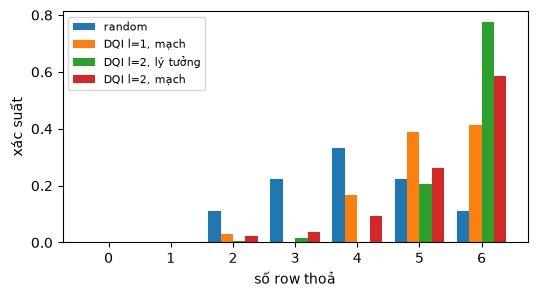

In [24]:
fig, ax = plt.subplots(figsize=(6, 3))
levels = np.arange(lin.m + 1)
for i, (name, P) in enumerate(dists.items()):
    ax.bar(levels + (i - 1.5) * 0.2, [P[s == v].sum() for v in levels], width=0.2, label=name)
ax.set_xlabel("số row thoả")
ax.set_ylabel("xác suất")
ax.legend(fontsize=8)
plt.show()

## 12. Cả ngày: so DQI với random, CP-SAT và QAOA

### 12.1 Bài đầy đủ, có quota

**Mục tiêu.** Chạy bài toán đầy đủ của thứ 2 (8 lớp, có quota) và so các cách theo cùng một thước đo.

**Input.** Bộ `day` ở phần 2.

**Output.** Lịch tối ưu, và với mỗi cách: số qubit, $P(\text{tối ưu})$, $N_{95}$.

**Phương pháp.**
- Thước đo chung là $V(a)$: số constraint gốc lịch $a$ vi phạm (lớp không có teacher dạy được, cặp trùng giờ cùng teacher, teacher ngoài quota). Lịch tối ưu có $V=V^\star$, tìm bằng vét cạn và kiểm bằng CP-SAT (`classical`).
- DQI teacher-index (phần 4, không có quota): mạch cần $m+\lceil\log_2p\rceil(m+n)$ qubit, quá nhiều để mô phỏng, nên dùng trạng thái lý tưởng. Ở $\ell=1$ nó trùng với mạch khi $\varepsilon_1=0$, như phần 11 đã kiểm trên buổi sáng.
- DQI nhị phân $x_{s,l}$ có quota cứng, đã gộp các row trùng hệ số (`formulations.binary`, DQITT-003): $\mathbb{F}_p^{16}$ quá lớn để liệt kê, nên dùng công thức đóng $\ell=1$ trên các vector 0/1.
- QAOA của ttqaoa: `solve_qaoa` nguyên bản (QUBO của ttqaoa, $p=1$, 20 lần khởi tạo, COBYLA), rồi tính phân bố chính xác tại góc tốt nhất.
- Random: chọn đều một teacher dạy được cho mỗi lớp.

In [25]:
v_star, best_day = optimum(day)
t0 = time.perf_counter()
v_cp, a_cp = cpsat_optimum(day)
print(f"V* = {v_star} ({len(best_day)} lịch tối ưu); CP-SAT cho {v_cp} trong {time.perf_counter() - t0:.3f} s")


def timetable(a):
    for ca, slots in cas.items():
        cells = [f"{slot} {sec} {subj}: {short(T[a[j]]) if a[j] >= 0 else '-'}"
                 for j, (sec, subj, slot) in enumerate(rows) if slot in slots]
        print(f"   ca {ca}: " + "  |  ".join(cells))


print("lịch của CP-SAT:")
timetable(a_cp)

V* = 0 (32 lịch tối ưu); CP-SAT cho 0 trong 0.014 s
lịch của CP-SAT:
   ca 1: A24 AI1910 CSD203: a  |  A25 AI1912 CSD204: anhbn5
   ca 2: A42 AI1914 CSD203: Ngadtt22  |  A52 AI1916 CSD204: a
   ca 3: P24 AI1918 CSD203: a  |  P25 AI1920 CSD204: anhbn5
   ca 4: P42 AI2007 PFP191: Ngadtt22  |  P52 AI1922 CSD203: a


In [26]:
p_opt, qubits = {}, {}
E_day = np.array(list(product(*[sorted(E) for E in day.eligible])))
p_opt["random trên teacher dạy được"], qubits["random trên teacher dạy được"] = (violations(day, E_day) == v_star).mean(), 0

lin_day = build(day)
X_day = all_x(lin_day.p, lin_day.n)
opt_day = violations(day, np.where(X_day < len(T), X_day, -1)) == v_star
eps = decoder_failure(lin_day, 2)
print(f"teacher-index: p={lin_day.p}, n={lin_day.n}, m={lin_day.m}, d={code_distance(lin_day, 3)}, "
      f"ε_1={eps[1]:.3f}, ε_2={eps[2]:.3f}, qubit={n_wires(lin_day)}")
psi_day = {}
for l in (1, 2):
    psi_day[l], _, _ = ideal_state(lin_day, l)
    name = f"DQI teacher-index l={l}" + (" (decoder lý tưởng)" if l == 2 else "")
    p_opt[name], qubits[name] = (np.abs(psi_day[l]) ** 2)[opt_day].sum(), n_wires(lin_day)

linb, pairs = binary(day, "hard", merge=True)
Xb = np.array(list(product((0, 1), repeat=linb.n)))
decoded = [to_assignment(x, pairs, len(day.sections)) for x in Xb]
valid = np.array([a is not None for a in decoded])
Ab = np.array([a if a is not None else np.full(len(day.sections), -1) for a in decoded])
Pb = l1_probs(linb, l1_weights(linb), Xb)
print(f"nhị phân quota cứng: p={linb.p}, n={linb.n}, m={linb.m}, không có codeword trọng số <= 2: "
      f"{code_distance(linb, 2) is None}, ε_1={decoder_failure(linb, 1)[1]:.3f}, qubit={n_wires(linb)}")
print(f"   P(một lần đo là lịch 0/1 hợp lệ) = {Pb[valid].sum():.3g}")
p_opt["DQI nhị phân có quota l=1"], qubits["DQI nhị phân có quota l=1"] = Pb[valid & (violations(day, Ab) == v_star)].sum(), n_wires(linb)

teacher-index: p=3, n=8, m=12, d=3, ε_1=0.000, ε_2=0.182, qubit=52


nhị phân quota cứng: p=11, n=16, m=31, không có codeword trọng số <= 2: True, ε_1=0.000, qubit=219
   P(một lần đo là lịch 0/1 hợp lệ) = 1.15e-11


In [27]:
problem = qubo(OUT / "day")
t0 = time.perf_counter()
_, params = solve_qaoa(problem, depth=1, shots=20000, restarts=20)
Pq = qaoa_probs(problem, params)
a_q, valid_q = bits_to_assignment(index_to_bits(np.arange(2**problem.n_qubits), problem.n_qubits), problem)
p_opt["QAOA ttqaoa p=1"], qubits["QAOA ttqaoa p=1"] = Pq[valid_q & (violations(day, a_q) == v_star)].sum(), problem.n_qubits
print(f"QAOA: {problem.n_qubits} qubit, tối ưu góc mất {time.perf_counter() - t0:.0f} s")

print(f"\n{'cách':42s} {'qubit':>5s} {'P(tối ưu)':>10s} {'N95':>12s}")
for name in sorted(p_opt, key=p_opt.get, reverse=True):
    print(f"{name:42s} {qubits[name]:5d} {p_opt[name]:10.3g} {shots_to_hit(p_opt[name], 0.95):>12}")

QAOA: 16 qubit, tối ưu góc mất 93 s

cách                                       qubit  P(tối ưu)          N95
random trên teacher dạy được                   0      0.125           23
DQI teacher-index l=2 (decoder lý tưởng)      52     0.0923           31
DQI teacher-index l=1                         52      0.029          102
QAOA ttqaoa p=1                               16    0.00324          924
DQI nhị phân có quota l=1                    219   7.89e-14 37950995079829


Lịch có xác suất cao nhất dưới DQI teacher-index $\ell=1$ (teacher ảo được ghi là `-`), kèm số constraint vi phạm và số lớp của từng teacher so với quota:

In [28]:
y = X_day[np.argmax(np.abs(psi_day[1]) ** 2)]
a = np.where(y < len(T), y, -1)
timetable(a)
print("   V =", violations(day, a), "; V* =", v_star)
print("   số lớp / quota:", {short(t): (int((a == i).sum()), day.quota[i]) for i, t in enumerate(T)})

   ca 1: A24 AI1910 CSD203: Ngadtt22  |  A25 AI1912 CSD204: anhbn5
   ca 2: A42 AI1914 CSD203: Ngadtt22  |  A52 AI1916 CSD204: anhbn5
   ca 3: P24 AI1918 CSD203: Ngadtt22  |  P25 AI1920 CSD204: anhbn5
   ca 4: P42 AI2007 PFP191: anhbn5  |  P52 AI1922 CSD203: Ngadtt22
   V = 2 ; V* = 0
   số lớp / quota: {'anhbn5': (4, (1, 99)), 'Ngadtt22': (4, (1, 2)), 'a': (0, (1, 4))}


### 12.2 Cùng một bài: bỏ quota ở cả hai phía

**Mục tiêu.** So DQI teacher-index (52 qubit, không quota) với QAOA trên đúng cùng một bài: eligibility và conflict, không quota.

**Input.** Bộ `day`, bỏ quota.

**Output.** Với mỗi cách: số qubit, $P(\text{tối ưu})$, $N_{95}$; với QAOA thêm thời gian tối ưu góc.

**Phương pháp.**
- Thước đo: $V$ chỉ đếm lớp không có teacher dạy được và cặp trùng giờ cùng teacher. $V^\star$ tính lại bằng vét cạn và CP-SAT.
- QAOA với QUBO của ttqaoa, trọng số quota bằng 0 (`qubo(..., w_quota=0)`). QUBO này giữ term conflict $(x_{s,t}+x_{s',t})^2$ của ttqaoa, phạt cả khi chỉ một trong hai lớp được giao cho $t$.
- QAOA với QUBO chính xác (`ttqaoa.exact_qubo`): $\sum_s(\sum_t x_{s,t}-1)^2+\sum x_{s,t}x_{s',t}$ trên các cặp trùng giờ. Năng lượng của một lịch bằng đúng $V$; `tests/test_ttqaoa.py` kiểm điều này trên mọi lịch của `inst_01`.
- Cả hai QAOA dùng `solve_qaoa` nguyên bản của ttqaoa: $p=1$, 20 lần khởi tạo COBYLA, 16 qubit.
- DQI teacher-index $\ell=1,2$ (trạng thái lý tưởng ở 12.1) và random.

**Lý do.** Bảng ở 12.1 chấm cả quota, trong khi DQI teacher-index không biết quota. Ở đây hai phía giải cùng một bài và được chấm cùng một $V$. Ô đầu kiểm rằng, với bộ này, số row DQI bị hỏng bằng đúng $V$ ở mọi lịch, tức DQI và QUBO chính xác tối ưu cùng một hàm.

In [29]:
from dataclasses import replace

from dqitt.ttqaoa import exact_qubo, with_cost

day_nq = replace(day, quota=None)
A_day = np.where(X_day < len(T), X_day, -1)
print("số row DQI hỏng = V ở mọi lịch:", bool((lin_day.m - lin_day.count(X_day) == violations(day_nq, A_day)).all()))
v_nq, best_nq = optimum(day_nq)
v_cp_nq, _ = cpsat_optimum(day_nq)
print(f"không quota: V* = {v_nq} ({len(best_nq)} lịch tối ưu); CP-SAT cho {v_cp_nq}")

số row DQI hỏng = V ở mọi lịch: True
không quota: V* = 0 (81 lịch tối ưu); CP-SAT cho 0


In [30]:
p_nq, q_nq, secs, angles, dists_nq = {}, {}, {}, {}, {}
p_nq["random trên teacher dạy được"], q_nq["random trên teacher dạy được"] = (violations(day_nq, E_day) == v_nq).mean(), 0
opt_nq = violations(day_nq, A_day) == v_nq
opt_q = valid_q & (violations(day_nq, a_q) == v_nq)
p_nq["random trên F_3^8 (không gian của DQI)"], q_nq["random trên F_3^8 (không gian của DQI)"] = opt_nq.mean(), 0
p_nq["random trên 2^16 bitstring (không gian QAOA)"], q_nq["random trên 2^16 bitstring (không gian QAOA)"] = opt_q.mean(), 0
for l in (1, 2):
    name = f"DQI teacher-index l={l}" + (" (decoder lý tưởng)" if l == 2 else "")
    p_nq[name], q_nq[name] = (np.abs(psi_day[l]) ** 2)[opt_nq].sum(), n_wires(lin_day)

for name, prob in {"QAOA p=1, QUBO ttqaoa (w_quota=0)": qubo(OUT / "day", w_quota=0),
                   "QAOA p=1, QUBO chính xác": with_cost(problem, exact_qubo(problem))}.items():
    t0 = time.perf_counter()
    _, params = solve_qaoa(prob, depth=1, shots=20000, restarts=20)
    secs[name] = time.perf_counter() - t0
    angles[name], dists_nq[name] = params, qaoa_probs(prob, params)
    p_nq[name], q_nq[name] = dists_nq[name][opt_q].sum(), prob.n_qubits

print(f"{'cách':45s} {'qubit':>5s} {'P(tối ưu)':>10s} {'N95':>6s} {'tối ưu góc':>11s}")
for name in sorted(p_nq, key=p_nq.get, reverse=True):
    t = f"{secs[name]:.0f} s" if name in secs else "-"
    print(f"{name:45s} {q_nq[name]:5d} {p_nq[name]:10.3g} {shots_to_hit(p_nq[name], 0.95):>6} {t:>11s}")

cách                                          qubit  P(tối ưu)    N95  tối ưu góc
random trên teacher dạy được                      0      0.316      8           -
QAOA p=1, QUBO ttqaoa (w_quota=0)                16      0.316      8        24 s
DQI teacher-index l=2 (decoder lý tưởng)         52      0.234     12           -
QAOA p=1, QUBO chính xác                         16      0.206     13        22 s
DQI teacher-index l=1                            52     0.0735     40           -
random trên F_3^8 (không gian của DQI)            0     0.0123    242           -
random trên 2^16 bitstring (không gian QAOA)      0    0.00124   2423           -


QAOA với QUBO của ttqaoa có thể cho đúng mức của random trên teacher dạy được. Ô dưới kiểm vì sao: góc $\gamma$ tìm được, phân bố trên các lịch mỗi lớp đúng một teacher, và năng lượng QUBO của các lịch đó.

In [31]:
from dqitt.ttqaoa import energies

name = "QAOA p=1, QUBO ttqaoa (w_quota=0)"
P = dists_nq[name]
onehot = valid_q & (a_q >= 0).all(axis=1)
e = energies(qubo(OUT / "day", w_quota=0))
print(f"gamma = {angles[name][0, 0]:.5f}, pi/2 = {np.pi / 2:.5f}")
print(f"{onehot.sum()} lịch mỗi lớp một teacher: tổng xác suất {P[onehot].sum():.4f}, "
      f"mỗi lịch từ {P[onehot].min():.5f} tới {P[onehot].max():.5f} (1/256 = {1 / 256:.5f})")
print("năng lượng QUBO của các lịch đó chia 4 dư:", sorted({float(x) for x in np.round(e[onehot] % 4, 6)}))

gamma = 1.57076, pi/2 = 1.57080
256 lịch mỗi lớp một teacher: tổng xác suất 1.0000, mỗi lịch từ 0.00391 tới 0.00391 (1/256 = 0.00391)
năng lượng QUBO của các lịch đó chia 4 dư: [0.0]


Nếu ô trên cho $\gamma\approx\pi/2$ và năng lượng chia 4 đều dư 0, thì pha $e^{-i\gamma E}=e^{-i2\pi k}$ giống nhau trên mọi lịch mỗi lớp một teacher: QAOA $p=1$ không phân biệt được lịch trùng giờ với lịch đúng, và chỉ còn tách các lịch đủ một teacher mỗi lớp khỏi phần còn lại. Hệ số 4 đến từ term conflict $W_c^2(x_{s,t}+x_{s',t})^2$ với $W_c=2$. QUBO chính xác có term conflict hệ số 1 nên không rơi vào trường hợp này.

## 13. Tóm tắt

- **Dữ liệu.** `toy` có mã môn thật và khung 4 ca mỗi ngày, nhưng thiếu lịch rảnh cho 9 mã slot đang dùng, nên 11/18 lớp không ai dạy được (phần 1). Ngày thứ 2 dựng từ `toy` có 8 lớp của 3 môn (CSD203, CSD204, PFP191), 3 teacher, 4 cặp trùng giờ, mỗi cặp là hai lớp cùng ca. Lịch rảnh được đặt là rảnh hết, vì giữ lịch của `toy` thì 6/8 lớp không ai dạy được (phần 2).
- **Formulation buổi sáng.** $p=3$, $n=4$, $m=6$; 9 lịch đạt 6/6. Code có $d=3$: mỗi cạnh conflict cộng hai row eligibility ở hai đầu là một codeword trọng số 3 (phần 4, 5).
- **Từng stage của mạch khớp công thức** (26 qubit): Dicke cho $P(k)=w_k^2$; `load` cho đúng phân bố error và trả flag về 0; `syndrome` cho đúng phân bố của $B^Te$ (phần 7 đến 9).
- **Công thức trọng số của Jordan et al. lệch** vì $2\ell+1<d$ không thoả: ở $\ell=1$ nó cho $w=[0.7559, 0.6547]$ và dự đoán $\langle s\rangle/m=0.8333$, trong khi tính trực tiếp cho $w=[0.7071, 0.7071]$ và $0.8591$ (phần 6).
- **Giải mã là điểm nghẽn.** Ở $\ell=1$ bảng tra luôn đúng và mạch trùng trạng thái lý tưởng. Ở $\ell=2$, $\varepsilon_2=0.4$, thanh ghi error chỉ về 0 với xác suất 0.866, và $P(\text{tối ưu})$ của mạch là 0.586 so với 0.774 nếu decoder không sai (phần 10, 11).
- **Buổi sáng, DQI cần ít lần đo hơn random:** $N_{95}$ bằng 6 ở $\ell=1$ so với 26 (phần 11).
- **Cả ngày, có quota** (phần 12.1): có 32 lịch không vi phạm gì, CP-SAT tìm ra trong 0.014 giây. $N_{95}$: random trên teacher dạy được 23; DQI teacher-index 102 ở $\ell=1$ và 31 ở $\ell=2$ với decoder lý tưởng (52 qubit, không có quota); QAOA của ttqaoa 924 (16 qubit); DQI có quota khoảng $3.8\times10^{13}$ (219 qubit, chỉ ra lịch 0/1 hợp lệ với xác suất $1.2\times10^{-11}$).
- Lịch có xác suất cao nhất dưới DQI teacher-index $\ell=1$ vi phạm 2 constraint, đều là quota: formulation này không biết quota (phần 12.1).
- **So trên cùng một bài, bỏ quota ở cả hai phía** (phần 12.2): có 81 lịch không vi phạm, và số row DQI hỏng bằng đúng $V$ ở mọi lịch. $N_{95}$: random trên teacher dạy được 8; QAOA với QUBO của ttqaoa 8; DQI $\ell=2$ với decoder lý tưởng 12 (52 qubit); QAOA với QUBO chính xác 13 (16 qubit); DQI $\ell=1$ 40 (52 qubit).
- **QAOA với QUBO của ttqaoa chỉ bằng random:** góc tối ưu $\gamma\approx\pi/2$, mọi lịch mỗi lớp một teacher có năng lượng là bội của 4, nên phân bố đầu ra đều $1/256$ trên 256 lịch đó và không còn thông tin về trùng giờ (phần 12.2).
- **So với random trên chính không gian tìm kiếm của mình,** DQI $\ell=1$ cần ít lần đo hơn khoảng 6 lần (40 so với 242 trên $\mathbb{F}_3^8$), QAOA với QUBO chính xác ít hơn khoảng 190 lần (13 so với 2,423 trên $2^{16}$ bitstring).